SetUp

In [1]:
# pip install opencv-python matplotlib numpy pandas

In [2]:
import re
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%config InlineBackend.figure_formats = ['jpeg']   # photos are much smaller as jpeg than png

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
FRAMES_DIR = RAW_DIR / 'frames'                         # aligned frames
CHECK_DIR = RAW_DIR / 'align_check'                     # before / after alignment pictures
REF_DIR = ROOT / 'data' / 'annotations' / 'references'  # one reference picture per video

FRAME_W, FRAME_H = 1920, 1080
EVERY = 15        # seconds between frames
MIN_FRAMES = 3    # short clips still give at least 3 frames
REDO = False      # True = extract every video again, False = only videos without frames

print('project folder:', ROOT)
print('frame size    :', FRAME_W, 'x', FRAME_H)

project folder: C:\Users\ASUS\.vscode\pcd\project-akhir
frame size    : 1920 x 1080


Step 1: Video List

In [3]:
def guess_video_info(file_name):
    name = Path(file_name).stem.lower()
    m = re.search(r'(\d{1,2})[-_.](\d{1,2})[-_.]\s*(\d{4})', name)    # 04-11-2026 or 10-11- 2026
    date = f'{m.group(3)}{int(m.group(2)):02d}{int(m.group(1)):02d}' if m else ''

    time = ''
    for t in ['morning', 'afternoon', 'evening', 'night']:
        if t in name:
            time = t

    who = ''
    for n in ['dinda', 'keiza', 'tobi']:
        if n in name:
            who = n

    weather = 'rain' if 'rain' in name else ''
    return date, time, weather, who


def video_id(date, time, weather, who):
    if weather == 'rain':
        time = time + 'rain'   # a rain clip gets its own id, e.g. 20261106_afternoonrain_keiza
    return f'{date}_{time}_{who}'

In [4]:
videos = pd.read_csv(RAW_DIR / 'videos.csv', dtype=str).fillna('')

for p in sorted(RAW_DIR.glob('*')):
    if p.suffix.lower() in ['.mp4', '.mov', '.avi', '.mkv'] and p.name not in list(videos['file']):
        date, time, weather, who = guess_video_info(p.name)
        videos.loc[len(videos)] = [p.name, date, time, weather, who, 'auto-guess, please check']
        print('new video:', p.name, '->', date, time, weather if weather else '?', who)

videos = videos.sort_values(['date', 'time', 'file']).reset_index(drop=True)
videos.to_csv(RAW_DIR / 'videos.csv', index=False)

fps_list, n_list, size_list = [], [], []
for i in range(len(videos)):
    cap = cv.VideoCapture(str(RAW_DIR / videos['file'][i]))
    fps_list.append(round(cap.get(cv.CAP_PROP_FPS), 2))
    n_list.append(int(cap.get(cv.CAP_PROP_FRAME_COUNT)))
    size_list.append(f'{int(cap.get(cv.CAP_PROP_FRAME_WIDTH))}x{int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))}')
    cap.release()

videos['video_id'] = [video_id(r['date'], r['time'], r['weather'], r['who']) for _, r in videos.iterrows()]
videos['fps'] = fps_list
videos['seconds'] = [round(n / f, 1) for n, f in zip(n_list, fps_list)]
videos['size'] = size_list
videos[['file', 'video_id', 'weather', 'fps', 'seconds', 'size']]

,file,video_id,weather,fps,seconds,size
0,raw_03-11-2026_afternoon_top_Keiza.MOV,20261103_afternoon_keiza,sunny,29.99,56.2,1920x1080
1,raw_03-11-2026_morning_top_Keiza.MOV,20261103_morning_keiza,sunny,29.99,139.7,1920x1080
2,raw_04-11-2026_dinda_afternoontop.mov,20261104_afternoon_dinda,sunny,55.88,122.6,3840x2160
3,raw_04-11-2026_evening_top_Keiza.mov,20261104_evening_keiza,dusk,30.00,120.7,1920x1080
4,raw_05-11-2026_afternoon_top_Dinda.MOV,20261105_afternoon_dinda,sunny,60.00,10.1,3840x2160
5,raw_5-11-2026_Night_Front-Top_Tobi.mp4,20261105_night_tobi,night,29.91,122.7,1440x2560
6,raw_06-11-2026_afternoonRain_top_Keiza.MOV,20261106_afternoonrain_keiza,rain,29.99,120.4,1920x1080
7,raw_06-11-2026_afternoon_top_Keiza.MOV,20261106_afternoon_keiza,cloudy,29.99,121.0,1920x1080
8,raw_9-11- 2026_Afternoon Rainy_Top_Tobi.mp4,20261109_afternoonrain_tobi,rain,29.65,124.6,1440x2560
9,raw_9-11-2026_Morning_Top_Tobi.mp4,20261109_morning_tobi,sunny,28.87,123.3,1440x2560


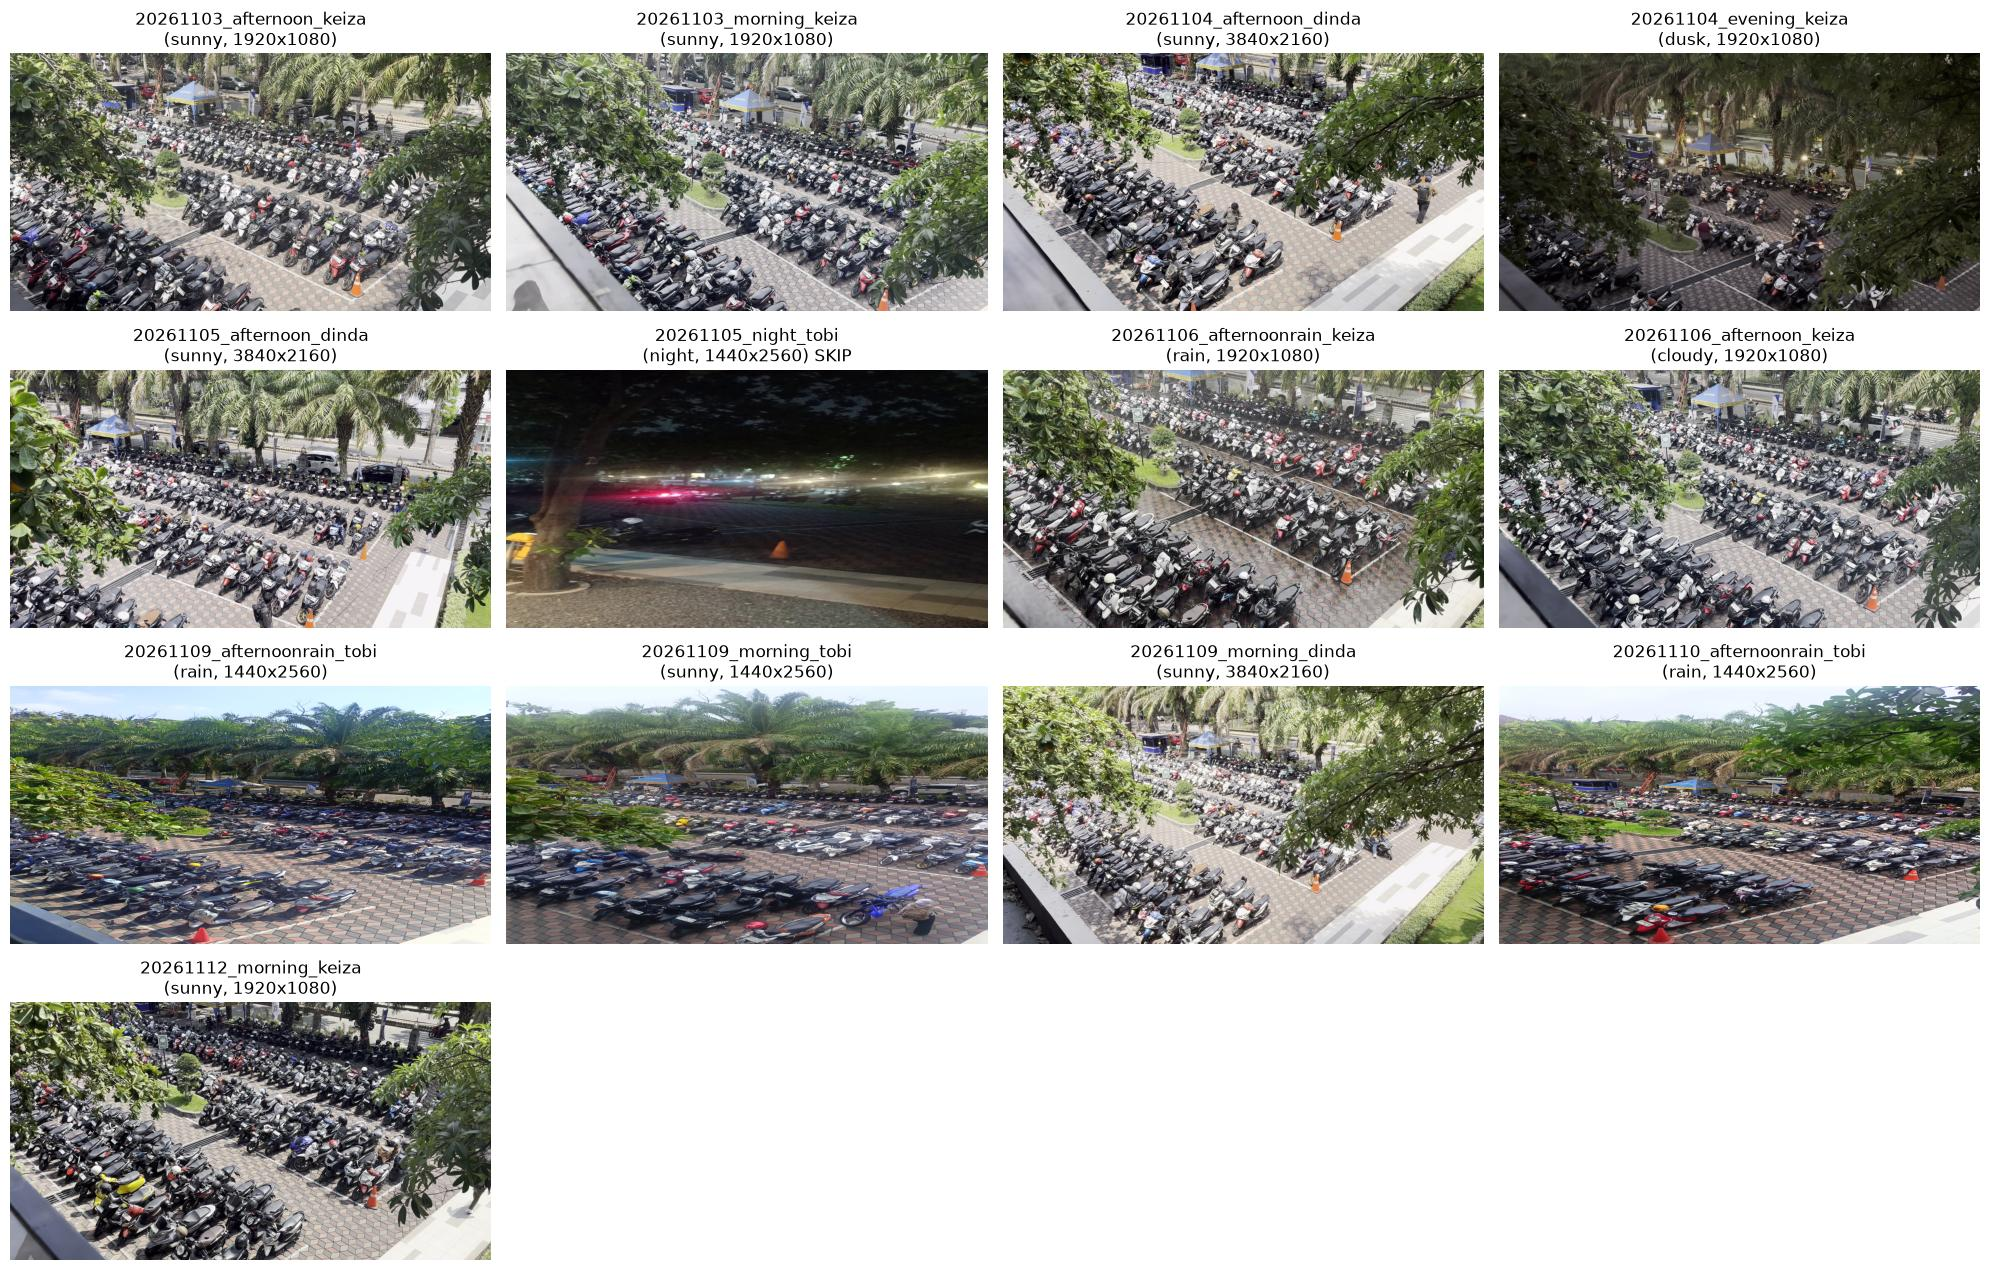

In [5]:
rows = int(np.ceil(len(videos) / 4))
plt.figure(figsize=(20, 3.2 * rows))
for i in range(len(videos)):
    cap = cv.VideoCapture(str(RAW_DIR / videos['file'][i]))
    cap.set(cv.CAP_PROP_POS_FRAMES, int(cap.get(cv.CAP_PROP_FRAME_COUNT)) // 2)
    ok, frame = cap.read()
    cap.release()

    skip = ' SKIP' if videos['note'][i].startswith('SKIP') else ''
    plt.subplot(rows, 4, i + 1)
    plt.imshow(frame[:, :, ::-1], aspect='auto')
    plt.title(f"{videos['video_id'][i]}\n({videos['weather'][i]}, {videos['size'][i]}){skip}")
    plt.axis('off')
plt.tight_layout()
plt.show()

semua video di `data/raw/` dicatat di `videos.csv`. kalau ada video baru, tanggal, waktu, perekam (dan hujan atau tidak) ditebak dari nama file nya, misalnya `raw_04-11-2026_evening_top_Keiza.mov` → `20261104`, `evening`, `keiza`. cuaca selain hujan (sunny, cloudy, dusk) diisi manual setelah melihat video nya. dari kolom ini dibuat **video id**, contohnya `20261104_evening_keiza`, yang dipakai sebagai nama referensi, roi dan frame. video hujan diberi id sendiri (`20261106_afternoonrain_keiza`) karena di hari dan jam yang sama keiza juga merekam video tanpa hujan, jadi id nya tidak boleh sama.

video nya tidak seragam: ada yang 1920 × 1080 (30 fps), 3840 × 2160 (4k, ±56–60 fps), dan video tobi direkam **portrait** 1440 × 2560. dua video dinda juga hanya ±10 detik. video malam tobi (`5-11-2026_Night_Front-Top`) diambil dari tempat lain (sejajar jalan, bukan dari lt 2 gedung g) dan terlalu gelap, jadi ditandai `SKIP` di kolom `note` dan tidak dipakai.

Step 2: Read Video and Sample Frames

In [6]:
PORTRAIT_CENTER = 0.66   # portrait clips: keep the 16:9 band around 66% of the height (the front rows)


def read_frame(cap, idx):
    cap.set(cv.CAP_PROP_POS_FRAMES, idx)
    ok, frame = cap.read()
    if not ok:
        return None
    h, w = frame.shape[:2]
    if h > w:                                   # portrait clip -> landscape 16:9 crop
        crop_h = w * 9 // 16
        y0 = int(PORTRAIT_CENTER * h - crop_h / 2)
        y0 = min(max(0, y0), h - crop_h)
        frame = frame[y0:y0 + crop_h]
    if frame.shape[1] != FRAME_W or frame.shape[0] != FRAME_H:
        frame = cv.resize(frame, (FRAME_W, FRAME_H), interpolation=cv.INTER_AREA)   # 4k -> 1080p
    return frame


def sample_indices(n_frames, fps):
    step = round(EVERY * fps)
    if n_frames // step < MIN_FRAMES:      # short clip: take MIN_FRAMES frames spread over the clip
        step = max(1, n_frames // MIN_FRAMES)
    return list(range(0, n_frames, step))

video   : raw_03-11-2026_afternoon_top_Keiza.MOV
video id: 20261103_afternoon_keiza
frames  : 1686 (56.2 s at 29.99 fps)
sampled : 4 frames at t = [0, 15, 30, 45] s


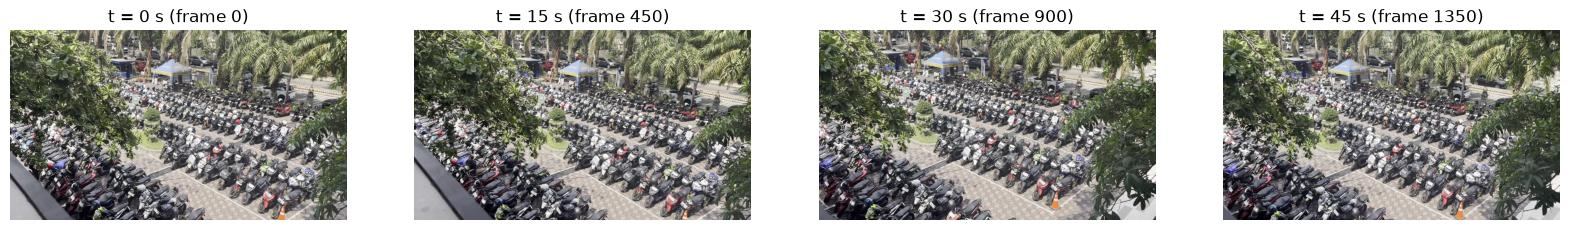

In [7]:
DEMO = 0   # which row of videos to use for the step-by-step demo

row = videos.iloc[DEMO]
cap = cv.VideoCapture(str(RAW_DIR / row['file']))
fps = cap.get(cv.CAP_PROP_FPS) or 30.0
n_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

sample_idx = sample_indices(n_frames, fps)
samples = [read_frame(cap, i) for i in sample_idx]

print('video   :', row['file'])
print('video id:', row['video_id'])
print('frames  :', n_frames, f'({n_frames / fps:.1f} s at {fps:.2f} fps)')
print('sampled :', len(sample_idx), 'frames at t =', [round(i / fps) for i in sample_idx], 's')

plt.figure(figsize=(20, 6))
for k in range(min(4, len(samples))):
    plt.subplot(1, 4, k + 1)
    plt.imshow(samples[k][:, :, ::-1])
    plt.title(f't = {sample_idx[k] / fps:.0f} s (frame {sample_idx[k]})')
    plt.axis('off')
plt.show()

video dibaca dengan `cv.VideoCapture`. dari ribuan frame per video, kami hanya mengambil **1 frame tiap 15 detik**, karena frame yang berdekatan hampir sama persis (motor jarang keluar masuk dalam hitungan detik) dan hanya akan menambah data duplikat. untuk video pendek (±10 detik), jarak nya diperkecil supaya tetap ada minimal **3 frame**. video portrait dipotong menjadi pita 16:9 (1440 × 810) di sekitar 66% tinggi frame, karena di situ letak blok parkir depan. lalu semua frame di-resize ke **1920 × 1080**, jadi video 4k, 1080p dan portrait punya ukuran yang sama.

Step 3: Reference Frame (Sharpest Frame)

In [8]:
def sharpness(img):
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    return cv.Laplacian(gray, cv.CV_64F).var()


def find_reference(cap, fps, n_frames):
    # candidates: about 4 frames per second in the first 3 seconds
    cand_idx, cand_sharp, cand_img = [], [], []
    for idx in range(0, min(n_frames, int(3 * fps)), max(1, int(fps / 4))):
        frame = read_frame(cap, idx)
        if frame is None:
            break
        cand_idx.append(idx)
        cand_sharp.append(sharpness(frame))
        cand_img.append(frame)
    return cand_idx, cand_sharp, cand_img

In [9]:
cand_idx, cand_sharp, cand_img = find_reference(cap, fps, n_frames)
best = int(np.argmax(cand_sharp))
worst = int(np.argmin(cand_sharp))
ref = cand_img[best]

for k in range(len(cand_idx)):
    note = '<- reference' if k == best else ''
    print(f'frame {cand_idx[k]:4d} (t = {cand_idx[k] / fps:.2f} s): sharpness = {cand_sharp[k]:8.1f}', note)

frame    0 (t = 0.00 s): sharpness =   2469.4 
frame    7 (t = 0.23 s): sharpness =   2357.5 
frame   14 (t = 0.47 s): sharpness =   2427.4 
frame   21 (t = 0.70 s): sharpness =   2433.8 
frame   28 (t = 0.93 s): sharpness =   3118.3 <- reference
frame   35 (t = 1.17 s): sharpness =   2482.6 
frame   42 (t = 1.40 s): sharpness =   2627.6 
frame   49 (t = 1.63 s): sharpness =   2460.2 
frame   56 (t = 1.87 s): sharpness =   2778.5 
frame   63 (t = 2.10 s): sharpness =   2382.5 
frame   70 (t = 2.33 s): sharpness =   2507.4 
frame   77 (t = 2.57 s): sharpness =   2361.0 
frame   84 (t = 2.80 s): sharpness =   2892.6 


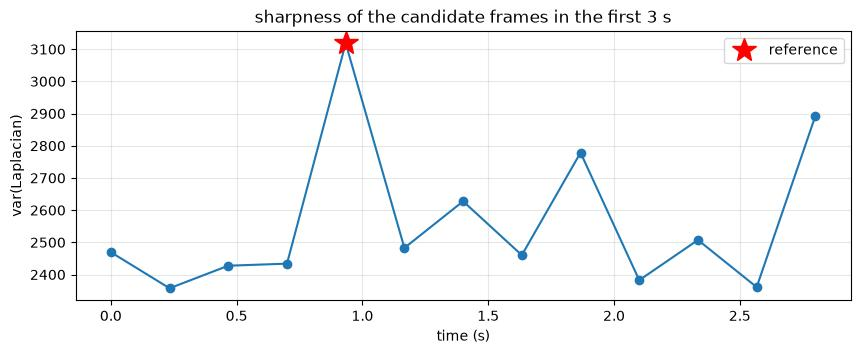

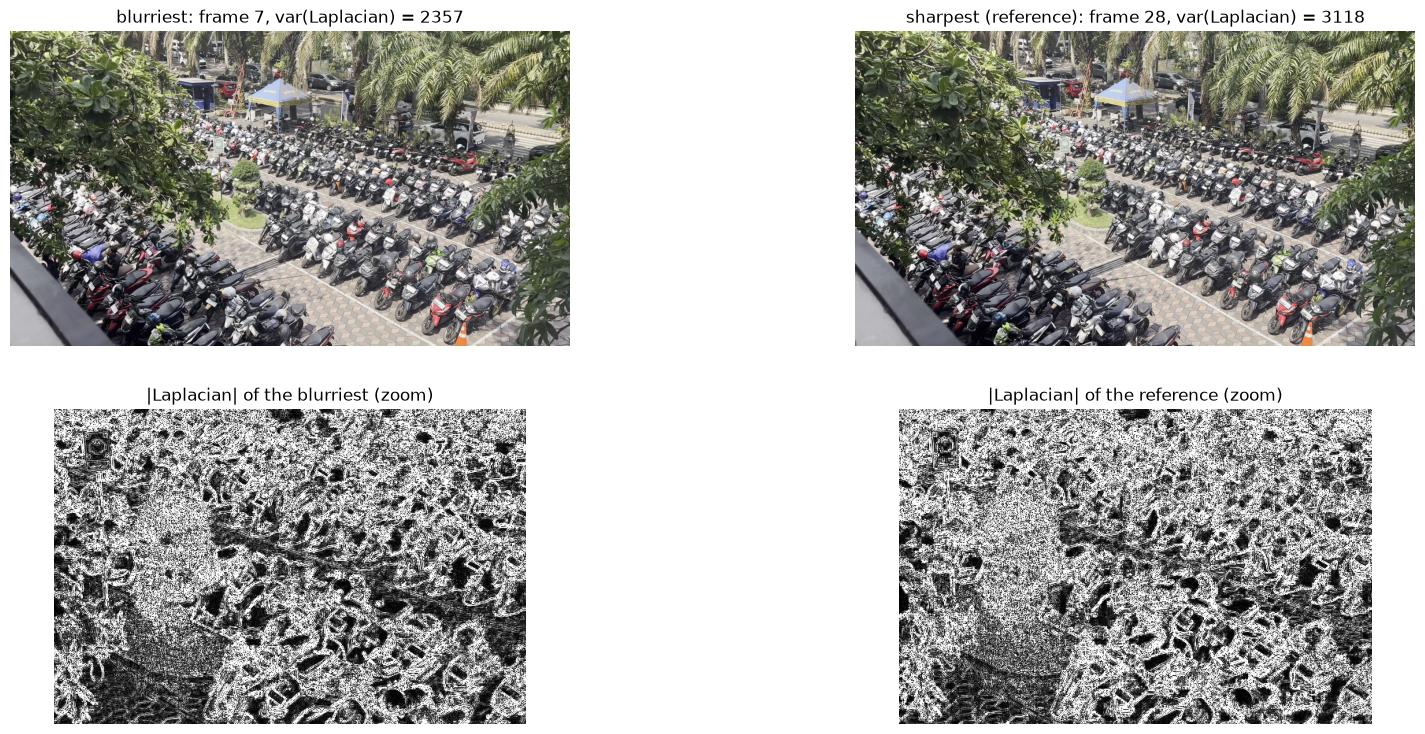

In [10]:
lap_worst = np.abs(cv.Laplacian(cv.cvtColor(cand_img[worst], cv.COLOR_BGR2GRAY), cv.CV_64F))
lap_best = np.abs(cv.Laplacian(cv.cvtColor(ref, cv.COLOR_BGR2GRAY), cv.CV_64F))
y0, x0 = FRAME_H // 2 - 200, FRAME_W // 2 - 300   # zoom on the middle so the difference is visible

plt.figure(figsize=(10, 3.5))
plt.plot(np.array(cand_idx) / fps, cand_sharp, 'o-')
plt.plot(cand_idx[best] / fps, cand_sharp[best], 'r*', markersize=18, label='reference')
plt.xlabel('time (s)')
plt.ylabel('var(Laplacian)')
plt.title('sharpness of the candidate frames in the first 3 s')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(20, 9))
plt.subplot(2, 2, 1)
plt.imshow(cand_img[worst][:, :, ::-1])
plt.title(f'blurriest: frame {cand_idx[worst]}, var(Laplacian) = {cand_sharp[worst]:.0f}')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.imshow(ref[:, :, ::-1])
plt.title(f'sharpest (reference): frame {cand_idx[best]}, var(Laplacian) = {cand_sharp[best]:.0f}')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.imshow(lap_worst[y0:y0 + 400, x0:x0 + 600], cmap='gray', vmax=60)
plt.title('|Laplacian| of the blurriest (zoom)')
plt.axis('off')
plt.subplot(2, 2, 4)
plt.imshow(lap_best[y0:y0 + 400, x0:x0 + 600], cmap='gray', vmax=60)
plt.title('|Laplacian| of the reference (zoom)')
plt.axis('off')
plt.show()

setiap video punya satu **frame referensi**, yaitu frame paling tajam dari 3 detik pertama (sekitar 4 kandidat per detik). ketajaman diukur dengan **variance of laplacian**: laplacian adalah turunan kedua yang menonjolkan tepi, jadi citra tajam punya banyak tepi kuat dan variance nya besar, sedangkan citra blur variance nya kecil. awal video sering blur karena tangan masih bergerak setelah menekan tombol rekam. referensi disimpan di `data/annotations/references/<video id>.jpg`, dan roi nanti digambar di atas gambar ini.

Step 4: Alignment (Image Registration)

In [11]:
WORK_W, WORK_H = 960, 540   # match on a half-size picture: faster, and enough detail
MIN_INLIERS = 40

sift = cv.SIFT_create(nfeatures=5000)
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
matcher = cv.BFMatcher(cv.NORM_L2)


def get_features(img):
    small = cv.resize(img, (WORK_W, WORK_H))
    gray = cv.cvtColor(small, cv.COLOR_BGR2GRAY)
    return sift.detectAndCompute(clahe.apply(gray), None)


def match_features(feat_a, feat_b):
    kp_a, des_a = feat_a
    kp_b, des_b = feat_b
    if des_a is None or des_b is None:
        return []
    good = []
    for pair in matcher.knnMatch(des_a, des_b, k=2):
        if len(pair) == 2 and pair[0].distance < 0.75 * pair[1].distance:   # Lowe's ratio test
            good.append(pair[0])
    return good

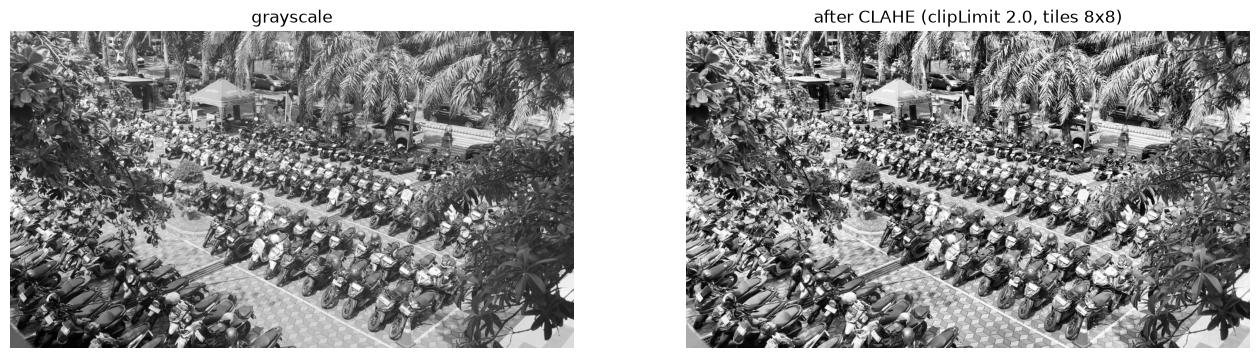

In [12]:
moving = samples[-1]   # a later frame, the hand has moved since the reference

ref_gray = cv.cvtColor(cv.resize(ref, (WORK_W, WORK_H)), cv.COLOR_BGR2GRAY)
mov_gray = cv.cvtColor(cv.resize(moving, (WORK_W, WORK_H)), cv.COLOR_BGR2GRAY)

plt.figure(figsize=(16, 5))
plt.subplot(1, 2, 1)
plt.imshow(mov_gray, cmap='gray')
plt.title('grayscale')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(clahe.apply(mov_gray), cmap='gray')
plt.title('after CLAHE (clipLimit 2.0, tiles 8x8)')
plt.axis('off')
plt.show()

**4a. preprocessing untuk matching.** frame diperkecil ke 960 × 540 (lebih cepat dan detail nya masih cukup), diubah ke grayscale, lalu diberi **CLAHE** (contrast limited adaptive histogram equalization). clahe meratakan histogram per tile 8 × 8, jadi bagian yang gelap (bayangan, sore hari) ikut punya kontras dan keypoint nya bisa ditemukan. ini hanya dipakai untuk mencari titik yang cocok, frame yang disimpan tetap frame asli.

keypoints (reference): 5000
keypoints (frame)    : 5000
matches after ratio  : 1591
RANSAC inliers       : 1514 (minimum 40)


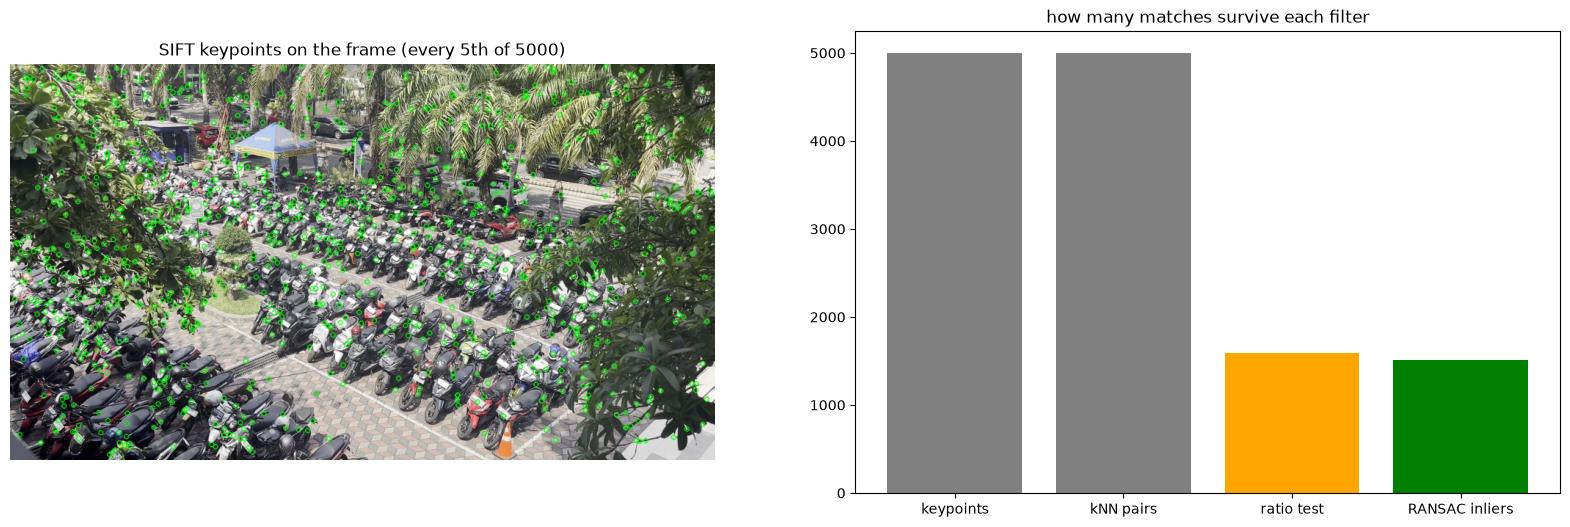

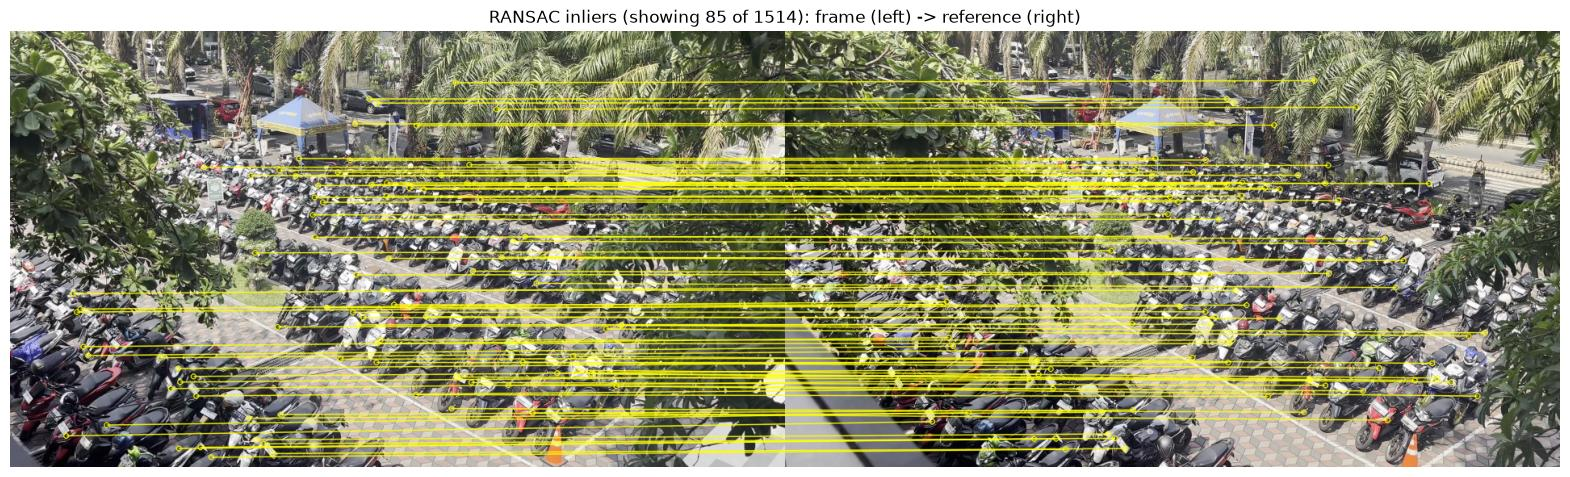

In [13]:
feat_ref = get_features(ref)
feat_mov = get_features(moving)
kp_ref, kp_mov = feat_ref[0], feat_mov[0]

pairs = matcher.knnMatch(feat_mov[1], feat_ref[1], k=2)
good = match_features(feat_mov, feat_ref)
src = np.float32([kp_mov[m.queryIdx].pt for m in good])
dst = np.float32([kp_ref[m.trainIdx].pt for m in good])
H_small, mask = cv.findHomography(src, dst, cv.RANSAC, 4.0)
inliers = int(mask.sum())

print('keypoints (reference):', len(kp_ref))
print('keypoints (frame)    :', len(kp_mov))
print('matches after ratio  :', len(good))
print('RANSAC inliers       :', inliers, f'(minimum {MIN_INLIERS})')

mov_small = cv.resize(moving, (WORK_W, WORK_H))
ref_small = cv.resize(ref, (WORK_W, WORK_H))

plt.figure(figsize=(20, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.drawKeypoints(mov_small, kp_mov[::5], None, color=(0, 255, 0))[:, :, ::-1])
plt.title(f'SIFT keypoints on the frame (every 5th of {len(kp_mov)})')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.bar(['keypoints', 'kNN pairs', 'ratio test', 'RANSAC inliers'],
        [len(kp_mov), len(pairs), len(good), inliers], color=['gray', 'gray', 'orange', 'green'])
plt.title('how many matches survive each filter')
plt.show()

inlier_matches = [m for m, keep in zip(good, mask.ravel()) if keep]
shown = inlier_matches[::max(1, len(inlier_matches) // 80)]   # ~80 lines so it stays readable
vis = cv.drawMatches(mov_small, kp_mov, ref_small, kp_ref, shown, None,
                     matchColor=(0, 255, 255), flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(20, 6))
plt.imshow(vis[:, :, ::-1])
plt.title(f'RANSAC inliers (showing {len(shown)} of {inliers}): frame (left) -> reference (right)')
plt.axis('off')
plt.show()

**4b. sift, ratio test dan ransac.** sift mencari keypoint (titik khas seperti sudut dan ujung benda) beserta descriptor 128 dimensi yang tahan terhadap perubahan skala, rotasi dan cahaya. setiap keypoint di frame dicocokkan ke 2 keypoint terdekat di referensi, lalu **lowe's ratio test** hanya menyimpan pasangan yang jarak terdekat nya < 0.75 × jarak kedua (pasangan yang tidak ambigu). sisa pasangan yang salah dibuang oleh **ransac**: berulang kali mengambil 4 pasangan acak, menghitung homography, dan memilih homography yang disetujui pasangan terbanyak (error < 4 piksel). pasangan yang setuju disebut **inlier**. kalau inlier < 40, frame dianggap terlalu blur dan dibuang.

In [14]:
def is_sane(H):
    # the 4 frame corners after warping must stay a convex quad of 0.5 - 2x the frame area
    corners = np.float32([[0, 0], [FRAME_W, 0], [FRAME_W, FRAME_H], [0, FRAME_H]]).reshape(-1, 1, 2)
    warped = cv.perspectiveTransform(corners, H).reshape(-1, 2)
    area = cv.contourArea(warped) / (FRAME_W * FRAME_H)
    return 0.5 < area < 2.0 and cv.isContourConvex(warped)


def find_homography(feat_frame, feat_ref):
    good = match_features(feat_frame, feat_ref)
    if len(good) < MIN_INLIERS:
        return None, len(good)

    src = np.float32([feat_frame[0][m.queryIdx].pt for m in good])
    dst = np.float32([feat_ref[0][m.trainIdx].pt for m in good])
    H_small, mask = cv.findHomography(src, dst, cv.RANSAC, 4.0)
    if H_small is None or int(mask.sum()) < MIN_INLIERS:
        return None, 0 if mask is None else int(mask.sum())

    S = np.diag([WORK_W / FRAME_W, WORK_W / FRAME_W, 1.0])   # half size -> full size
    H = np.linalg.inv(S) @ H_small @ S
    if not is_sane(H):
        return None, int(mask.sum())
    return H, int(mask.sum())


def warp_to_reference(img, H):
    return cv.warpPerspective(img, H, (FRAME_W, FRAME_H))

homography (full size, frame -> reference):
[[  0.8729  -0.0131 255.6152]
 [ -0.0202   0.9485  15.5698]
 [ -0.0001   0.       1.    ]]
inliers: 1514 | sane: True


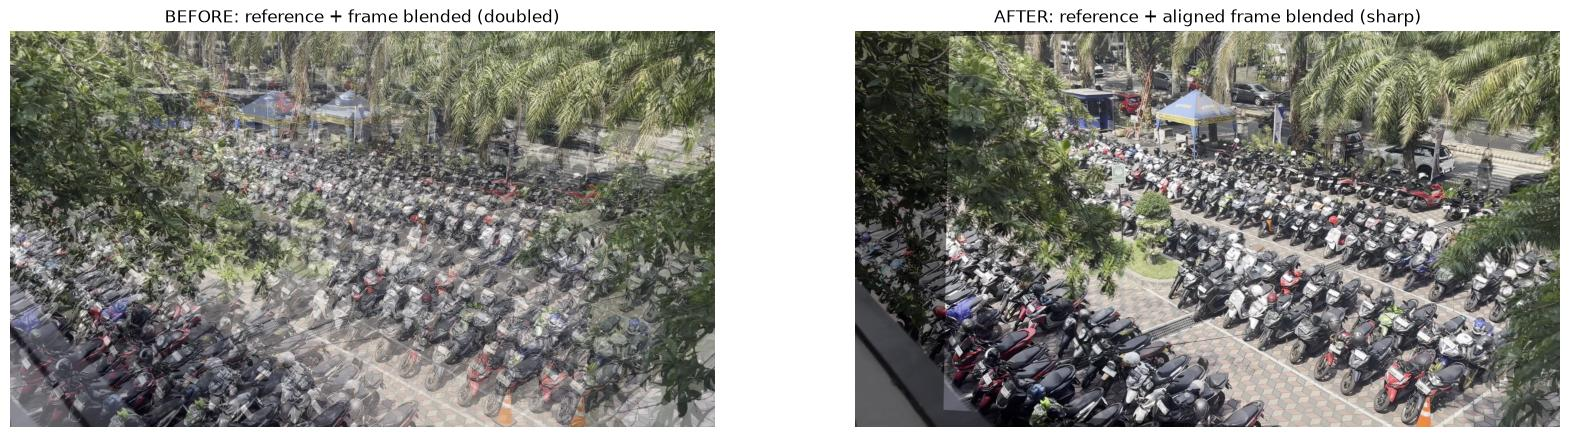

In [15]:
H, inl = find_homography(feat_mov, feat_ref)
aligned = warp_to_reference(moving, H)

np.set_printoptions(precision=4, suppress=True)
print('homography (full size, frame -> reference):')
print(H)
print('inliers:', inl, '| sane:', is_sane(H))

plt.figure(figsize=(20, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.addWeighted(ref, 0.5, moving, 0.5, 0)[:, :, ::-1])
plt.title('BEFORE: reference + frame blended (doubled)')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv.addWeighted(ref, 0.5, aligned, 0.5, 0)[:, :, ::-1])
plt.title('AFTER: reference + aligned frame blended (sharp)')
plt.axis('off')
plt.show()

**4c. warp.** homography adalah matriks 3 × 3 yang memetakan setiap titik (x, y) di frame ke posisi nya di referensi (proyeksi perspektif). karena dihitung di citra 960 piksel, matriks nya dikembalikan ke ukuran 1920 dengan H = S⁻¹ · H_small · S. sebelum dipakai, homography dicek dulu: keempat sudut frame setelah di-warp harus membentuk segi empat convex dengan luas 0.5 – 2 kali luas frame, supaya homography yang aneh (misalnya terbalik) tidak lolos. lalu `cv.warpPerspective` memindahkan frame ke posisi referensi, dan area yang tidak terlihat di frame asli menjadi hitam.

hasilnya terlihat di gambar blend: sebelum alignment frame dan referensi tidak berimpit (terlihat dobel), sesudah alignment gambar nya tajam. karena semua frame dari satu video sudah berimpit dengan referensi, **roi cukup digambar satu kali per video**, dan mask frame sebelumnya bisa langsung dipakai sebagai awal label frame berikutnya.

Step 5: Extract All Videos

In [16]:
def extract_video(row):
    vid = row['video_id']
    cap = cv.VideoCapture(str(RAW_DIR / row['file']))
    fps = cap.get(cv.CAP_PROP_FPS) or 30.0
    n_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

    # reference: keep the existing one (the roi is drawn on it), otherwise the sharpest early frame
    ref_file = REF_DIR / f'{vid}.jpg'
    if not ref_file.exists():
        cand_idx, cand_sharp, cand_img = find_reference(cap, fps, n_frames)
        cv.imwrite(str(ref_file), cand_img[int(np.argmax(cand_sharp))], [cv.IMWRITE_JPEG_QUALITY, 95])
    ref = cv.imread(str(ref_file))
    feat_ref = get_features(ref)

    for old in FRAMES_DIR.glob(f'{vid}_t*.jpg'):   # frames of an earlier run of this video
        old.unlink()

    rows, moved = [], []
    for idx in sample_indices(n_frames, fps):
        frame = read_frame(cap, idx)
        if frame is None:
            continue
        H, inl = find_homography(get_features(frame), feat_ref)
        if H is None:
            print(f'  t = {idx / fps:.0f} s: only {inl} inliers, too blurry to align -> skipped')
            continue
        aligned = warp_to_reference(frame, H)

        sec = int(round(idx / fps))
        name = f'{vid}_t{sec:03d}.jpg'
        cv.imwrite(str(FRAMES_DIR / name), aligned, [cv.IMWRITE_JPEG_QUALITY, 95])
        rows.append([name, row['file'], vid, row['date'], row['time'], row['weather'], row['who'], sec, 'every', inl])
        moved.append((np.mean(cv.absdiff(frame, ref)), frame, aligned))
    cap.release()

    if len(rows) == 0:
        print(f'{vid}: no frame could be aligned')
        return rows

    # before / after picture of the frame that moved most
    k = int(np.argmax([m[0] for m in moved]))
    diff, raw, aligned = moved[k]
    before = cv.resize(cv.addWeighted(ref, 0.5, raw, 0.5, 0), (640, 360))
    after = cv.resize(cv.addWeighted(ref, 0.5, aligned, 0.5, 0), (640, 360))
    cv.putText(before, 'BEFORE alignment', (10, 28), cv.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
    cv.putText(after, 'AFTER alignment', (10, 28), cv.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
    cv.imwrite(str(CHECK_DIR / f'{vid}.jpg'), np.hstack([before, after]))

    print(f"{vid}: {n_frames / fps:.0f} s -> {len(rows)} frames")
    return rows

In [17]:
cap.release()
FRAMES_DIR.mkdir(parents=True, exist_ok=True)
CHECK_DIR.mkdir(parents=True, exist_ok=True)
REF_DIR.mkdir(parents=True, exist_ok=True)

INDEX_COLS = ['frame', 'video', 'video_id', 'date', 'time', 'weather', 'who', 't_sec', 'reason', 'inliers']
index_file = FRAMES_DIR / 'frames_index.csv'
old_index = pd.read_csv(index_file, dtype={'date': str}) if index_file.exists() else pd.DataFrame(columns=INDEX_COLS)

all_rows = []
for i in range(len(videos)):
    row = videos.iloc[i]
    if row['note'].startswith('SKIP'):
        print(f"{row['video_id']}: skipped ({row['note']})")
        continue
    done = old_index[old_index['video_id'] == row['video_id']]
    if len(done) > 0 and not REDO:
        print(f"{row['video_id']}: already extracted ({len(done)} frames)")
        all_rows += done[INDEX_COLS].values.tolist()
    else:
        all_rows += extract_video(row)

frames_index = pd.DataFrame(all_rows, columns=INDEX_COLS).sort_values('frame').reset_index(drop=True)
frames_index.to_csv(index_file, index=False)
print(len(frames_index), 'frames listed in', index_file)

20261103_afternoon_keiza: already extracted (4 frames)
20261103_morning_keiza: already extracted (10 frames)
20261104_afternoon_dinda: already extracted (9 frames)
20261104_evening_keiza: already extracted (9 frames)
20261105_afternoon_dinda: already extracted (4 frames)
20261105_night_tobi: skipped (SKIP: different spot (street level, not Lt 2 Gedung G) and too dark)
20261106_afternoonrain_keiza: already extracted (9 frames)
20261106_afternoon_keiza: already extracted (9 frames)
20261109_afternoonrain_tobi: already extracted (9 frames)
20261109_morning_tobi: already extracted (9 frames)
20261109_morning_dinda: already extracted (3 frames)
20261110_afternoonrain_tobi: already extracted (9 frames)
20261112_morning_keiza: already extracted (8 frames)
92 frames listed in C:\Users\ASUS\.vscode\pcd\project-akhir\data\raw\frames\frames_index.csv


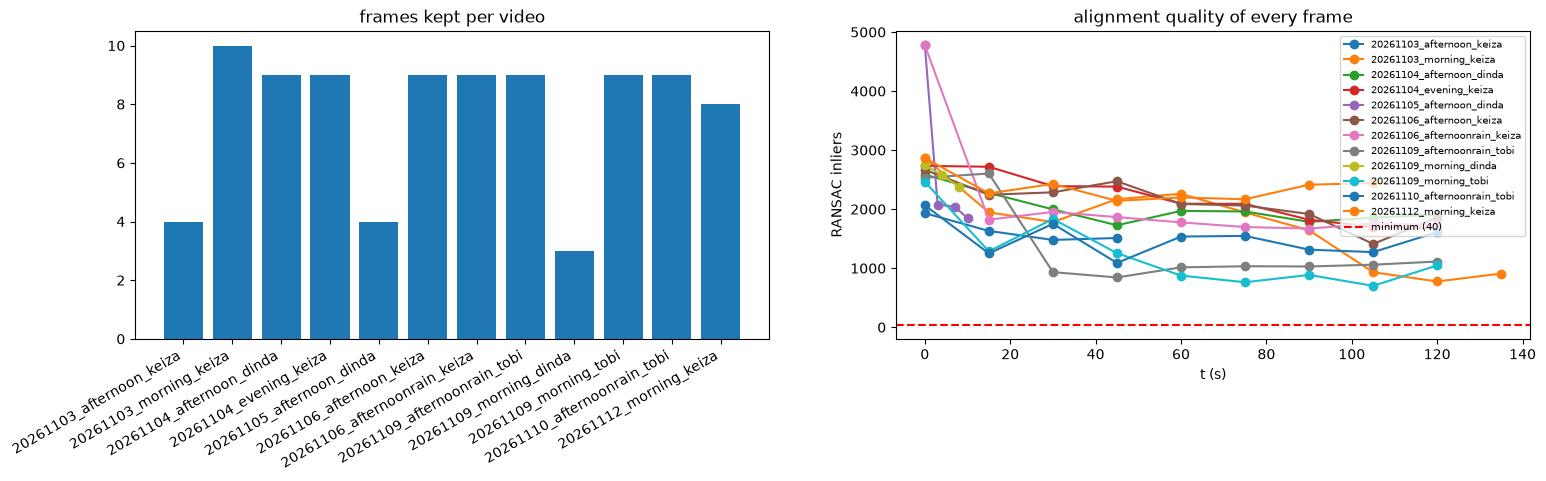

,weather,frames,min_inliers,mean_inliers
video_id,,,,
20261103_afternoon_keiza,sunny,4,1479,1638
20261103_morning_keiza,sunny,10,775,1722
20261104_afternoon_dinda,sunny,9,1727,2007
20261104_evening_keiza,dusk,9,1675,2178
20261105_afternoon_dinda,sunny,4,1848,2687
20261106_afternoon_keiza,cloudy,9,1411,2111
20261106_afternoonrain_keiza,rain,9,1671,2116
20261109_afternoonrain_tobi,rain,9,843,1351
20261109_morning_dinda,sunny,3,2382,2568


In [18]:
summary = frames_index.groupby('video_id').agg(weather=('weather', 'first'), frames=('frame', 'count'),
                                               min_inliers=('inliers', 'min'), mean_inliers=('inliers', 'mean'))
summary['mean_inliers'] = summary['mean_inliers'].round(0).astype(int)

plt.figure(figsize=(18, 4))
plt.subplot(1, 2, 1)
plt.bar(summary.index, summary['frames'])
plt.title('frames kept per video')
plt.xticks(rotation=30, ha='right')
plt.subplot(1, 2, 2)
for v, g in frames_index.groupby('video_id'):
    plt.plot(g['t_sec'], g['inliers'], 'o-', label=v)
plt.axhline(MIN_INLIERS, color='red', linestyle='--', label=f'minimum ({MIN_INLIERS})')
plt.xlabel('t (s)')
plt.ylabel('RANSAC inliers')
plt.title('alignment quality of every frame')
plt.legend(fontsize=7)
plt.show()

summary

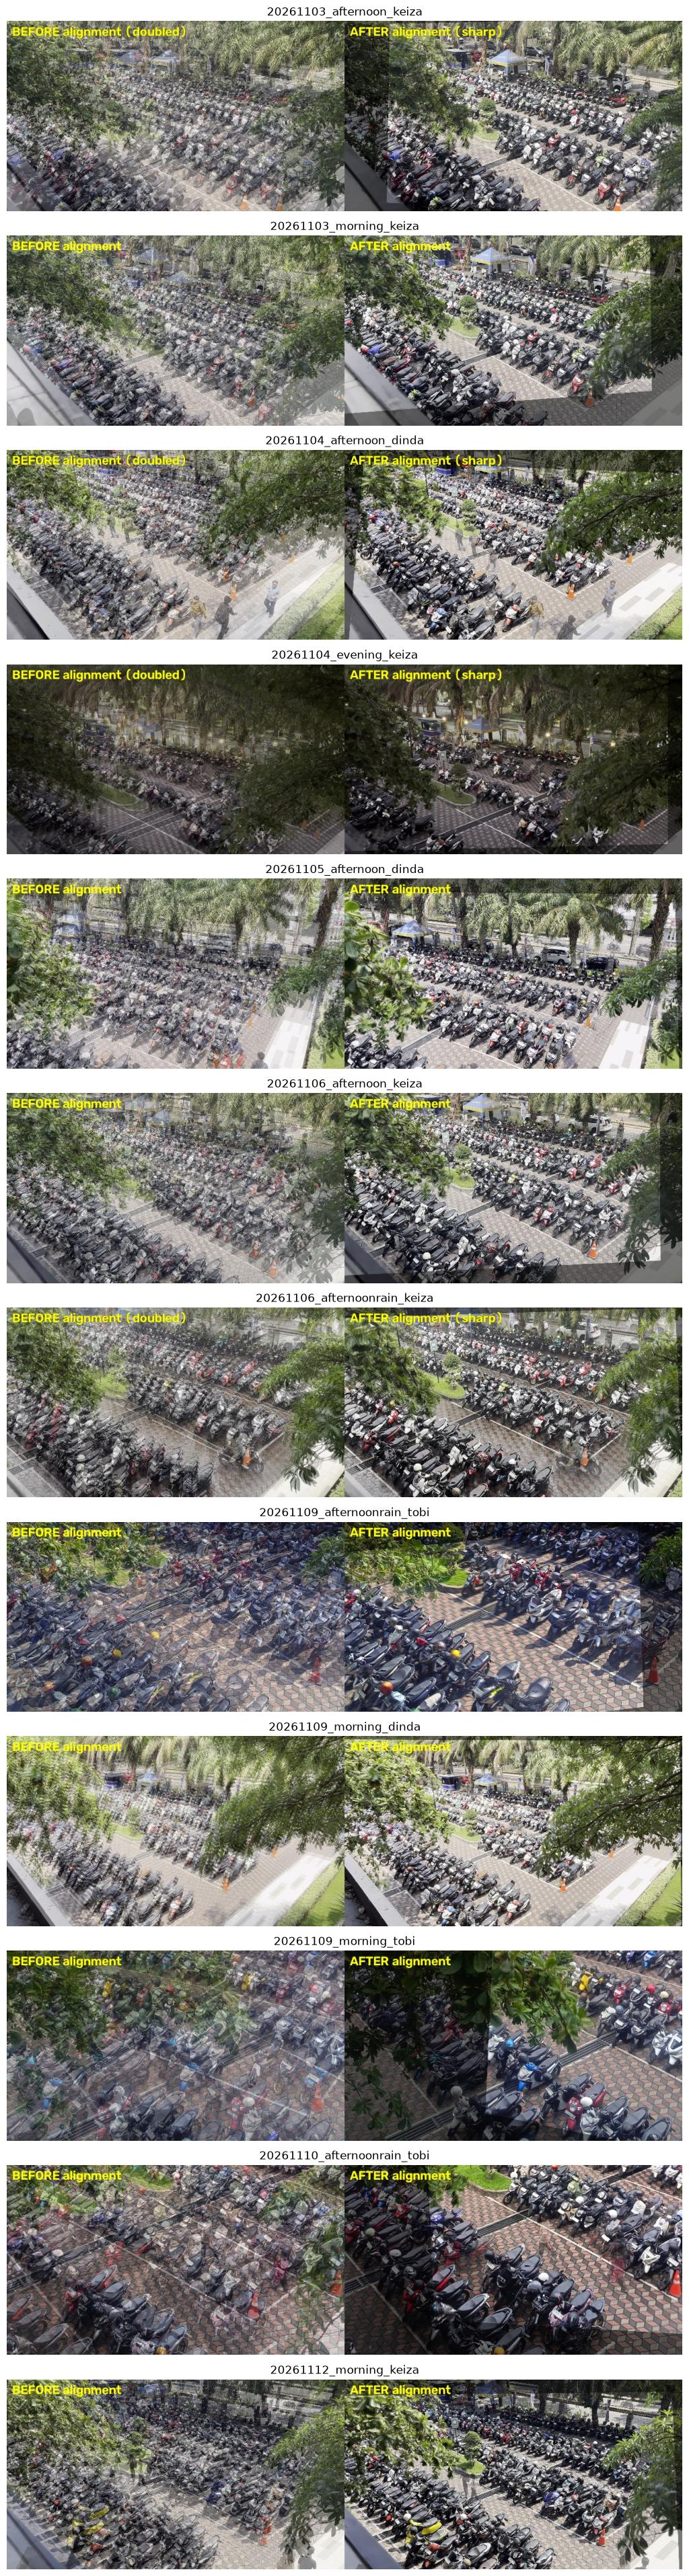

In [19]:
checks = sorted(CHECK_DIR.glob('*.jpg'))
plt.figure(figsize=(20, 3.2 * len(checks)))
for k in range(len(checks)):
    plt.subplot(len(checks), 1, k + 1)
    plt.imshow(cv.imread(str(checks[k]))[:, :, ::-1])
    plt.title(checks[k].stem)
    plt.axis('off')
plt.tight_layout()
plt.show()

langkah 2 sampai 4 dijalankan untuk semua video oleh `extract_video`. video yang sudah punya frame dilewati (kecuali `REDO = True`), jadi kalau ada video baru cukup jalankan ulang notebook ini. hasilnya: frame yang sudah di-align di `data/raw/frames/` (nama `<video id>_t<detik>.jpg`), daftar nya di `frames_index.csv` (termasuk jumlah inlier per frame), dan gambar cek before / after di `data/raw/align_check/` untuk frame yang paling banyak bergeser di setiap video.

Step 6: Summary

**1. ringkasan alur**

1. video mentah dicatat di `videos.csv` dan diberi video id (video hujan diberi id sendiri).
2. dari setiap video diambil 1 frame tiap 15 detik (minimal 3 frame untuk video pendek), video portrait dipotong ke 16:9, lalu semua di-resize ke 1920 × 1080.
3. frame paling tajam (variance of laplacian) di 3 detik pertama menjadi referensi.
4. setiap frame di-align ke referensi: clahe → sift → ratio test → ransac homography → cek homography → warp perspective. frame dengan inlier < 40 dibuang.

**2. hasil**

- dari 13 video, **12 dipakai** dan 1 dilewati (video malam tobi dari tempat lain). video nya berasal dari **7 hari** (3, 4, 5, 6, 9, 10 dan 12 november) dan 3 perekam.
- total **92 frame**: sunny 47, rain 27, dusk 9, cloudy 9. per waktu: pagi 30, siang 53, sore 9.
- **semua frame berhasil di-align**. inlier paling sedikit adalah 701 (`20261109_morning_tobi`), masih jauh di atas batas 40. video tobi punya inlier paling rendah (rata-rata ±1200–1500, video lain ±1600–2700) karena frame nya dipotong dari portrait lalu diperbesar 1.33×, jadi detail nya berkurang, dan kamera nya bergeser cukup jauh selama merekam (terlihat dari area hitam di pinggir hasil warp).

**3. keterbatasan**

- kondisi sore (dusk) hanya ada 9 frame dari 1 video, dan tidak ada frame malam yang bisa dipakai.
- alignment hanya dilakukan di dalam satu video. antar video (beda hari, beda orang, beda posisi berdiri) tidak bisa di-align dengan satu homography karena paralaks, jadi **roi digambar sekali per video** di notebook berikutnya.